# Module 5 — The 5 Whys

Part of the Root-Cause Analysis Playbook. Program and progress: [CURRICULUM.md](CURRICULUM.md).

## Why you're here: what this module is for

- The 5 Whys is the best-known root-cause technique: ask "why?" again and again until you reach a cause you can fix.
- It is also the most criticised: one chain of whys follows one cause, and real problems often have several.
- In DMAIC (Define, Measure, Analyze, Improve, Control), it is an **Analyze** tool, the simplest of this playbook's four cause-finding techniques (5 Whys, fishbone, cause mapping, fault trees).

**What this module produces:**
1. A full chain of whys on a revenue drop, every answer checked with a query.
2. A check of how much of the drop that chain explains.
3. A second chain that finds what the first one missed, and a money waterfall that splits the drop between the two causes.

## From the curriculum

> ## <u>Module 5 — The 5 Whys</u>
>
> **DMAIC phase:** Analyze (the simplest causal drill-down).
>
> **Concepts**
> - Asking "why?" until the answer is a cause that can be acted on (five is a
>   rule of thumb, not a rule), with an origin at Toyota (Sakichi Toyoda;
>   Taiichi Ohno made it part of the Toyota Production System)
> - Each "why" answered with evidence, not opinion
> - Known failure modes: one chain when there are several causes, stopping at a
>   symptom or at "human error", answers that cannot be checked, and different
>   people reaching different chains
> - When the 5 Whys is enough, and when to move to a fishbone or a cause map
>
> **Why it matters**
> It is the most widely used RCA technique and the most often criticised. A
> learner should be able to use it well and also say exactly where it breaks.
>
> **Worked example**
> Fresh, simulated: an online store's revenue dashboard down 17.8% week over
> week. It is simulated so that the two planted causes are known.
> - The first chain of whys, each answered by a query, follows the biggest
>   fall to Android: a new app version cannot take two card types.
> - That chain explains only about half of the drop. A second chain, starting
>   from a different first answer, finds the rest: a store moved to a new id
>   that the dashboard does not know.
> - A money waterfall splits the 16,788 drop between the two causes.
>
> **Resources**
> - [Five whys](https://en.wikipedia.org/wiki/Five_whys) (Wikipedia, ~10 min,
>   verified): the method, its origin at Toyota, and its known criticisms.
> - [The problem with "5 whys"](https://psnet.ahrq.gov/issue/problem-5-whys)
>   (U.S. Agency for Healthcare Research and Quality, a summary of Alan Card's
>   2017 critique in BMJ Quality & Safety, ~5 min, verified): why the method
>   oversimplifies problems with several causes.
>
> **Exercise type:** ask the next "why" on the second chain, and avoid stopping
> at "human error". Fully worked.
>
> **Interview angle:** "What are the limits of the 5 Whys?"

## Lesson

### The method

1. **State the problem** as a fact: what fell, by how much, when.
2. **Ask "why?"** and answer with a fact you have checked, not a guess.
3. **Ask "why?" of that answer**, and repeat.
4. **Stop** when the answer is a cause you can act on: usually a process that is missing or not working. Five is a rule of thumb; stop earlier or go further as the evidence allows.
5. **Check the result:** if this cause were fixed, how much of the problem would go away?

### Where it breaks

- **One chain, several causes.** Each "why" can have more than one true answer. Following only one answer follows only one cause.
- **Stopping too early:** at a symptom ("checkouts fail") or at "human error" ("someone forgot"). Neither tells you what to change.
- **Answers that cannot be checked.** When the data has no record of something, the next "why" is a guess. It must be marked as a Hypothesis, not added to the chain as fact.
- **Different people, different chains.** Two teams asking the same first question can follow different answers and reach different "root causes".

### When it is enough

When the problem has one cause and each step is easy to check, the 5 Whys is fast and enough. When there may be several causes, list them first (fishbone, Module 6) or map how they combine (cause mapping, Module 7).

## Worked example: the revenue dashboard is down 17.8%

**Data choice: fresh, simulated.** The lesson needs a case with two causes at once, with the truth known, so it can show what one chain of whys finds and what it misses. Every number in the simulation is a chosen example (`common.simulate_checkouts`, fixed seed). The two planted causes are revealed at the end.

**The data:** one row per checkout attempt at an online store over six weeks: date, platform (web, iOS, Android), app version, store, card type, amount, and whether the payment completed or failed (with an error code). Two views of revenue:
- **the order system:** every completed checkout
- **the dashboard:** completed checkouts for the stores on its store list (13 stores)

**The question the business asks:** *why is dashboard revenue down this week?* "This week" = 09.03–15.03.2026, compared with the week before, 02.03–08.03.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import common
from common import show, BLUE, ORANGE, AQUA, GREY

att, stores = common.simulate_checkouts()
done = att[att["status"] == "completed"]
dash = done[done["store_id"].isin(stores["store_id"])]
W5, W6 = ("2026-03-02", "2026-03-08"), ("2026-03-09", "2026-03-15")
wk = lambda df, W: df[(df["date"] >= W[0]) & (df["date"] <= W[1])]
print("What is in the data? (simulated)")
print(f"  checkout attempts = {len(att):,}")
print(f"  dates = {att['date'].min():%Y-%m-%d} to {att['date'].max():%Y-%m-%d}")
print(f"  stores on the dashboard's store list = {len(stores)}")
print(f"  missing values (app_version and error_code excluded: blank by design) = {int(att.replace('', np.nan).drop(columns=['app_version', 'error_code']).isna().sum().sum())}")
print()
print("The problem: dashboard revenue")
r5, r6 = wk(dash, W5)["amount"].sum(), wk(dash, W6)["amount"].sum()
print(f"  02.03-08.03 = {r5:,.0f}")
print(f"  09.03-15.03 = {r6:,.0f}")
print(f"  change = {r6 - r5:+,.0f} = {r6 / r5 - 1:+.1%}")

What is in the data? (simulated)
  checkout attempts = 8,806
  dates = 2026-02-02 to 2026-03-15
  stores on the dashboard's store list = 13
  missing values (app_version and error_code excluded: blank by design) = 0

The problem: dashboard revenue
  02.03-08.03 = 94,304
  09.03-15.03 = 77,516
  change = -16,788 = -17.8%


**Observation:** dashboard revenue fell from 94,304 to 77,516: a drop of 16,788, or 17.8%. (App version is blank for web checkouts, and the error code is blank for completed ones. That is by design, not missing data.)

**Problem statement:** dashboard revenue fell 17.8% (16,788) in 09.03–15.03 against 02.03–08.03.

**Is it really a drop?** Before asking why, check that the comparison week was a normal one, not a spike. Dashboard revenue, every week:

In [2]:
weekly = dash.assign(week=dash["date"].dt.to_period("W-SUN").dt.start_time).groupby("week")["amount"].sum()
for w, v in weekly.items():
    print(f"week of {w:%d.%m} = {v:,.0f}")
earlier = weekly.iloc[:4]
print(f"\nfour weeks before 02.03: lowest = {earlier.min():,.0f}, highest = {earlier.max():,.0f}")
print(f"09.03-15.03 below the lowest = {earlier.min():,.0f} − {weekly.iloc[-1]:,.0f} = {earlier.min() - weekly.iloc[-1]:,.0f}")

week of 02.02 = 93,490
week of 09.02 = 99,421
week of 16.02 = 93,689
week of 23.02 = 97,563
week of 02.03 = 94,304
week of 09.03 = 77,516

four weeks before 02.03: lowest = 93,490, highest = 99,421
09.03-15.03 below the lowest = 93,490 − 77,516 = 15,974


**Observation:** 02.03–08.03 (94,304) sits inside the range of the four weeks before it (93,490 to 99,421), so it was a normal week. 09.03–15.03 (77,516) is 15,974 below the lowest of them. The drop is real.

### Chain 1

**Why 1: why is dashboard revenue down?** Revenue = orders × average order value. Which one moved?

In [3]:
d5, d6 = wk(dash, W5), wk(dash, W6)
print("Dashboard orders and average order value:\n")
show(pd.DataFrame({"measure": ["orders", "average order value"],
                   "02.03-08.03": [f"{len(d5):,}", f"{d5['amount'].mean():.2f}"],
                   "09.03-15.03": [f"{len(d6):,}", f"{d6['amount'].mean():.2f}"],
                   "change": [f"{len(d6) / len(d5) - 1:+.1%}", f"{d6['amount'].mean() / d5['amount'].mean() - 1:+.1%}"]}))

Dashboard orders and average order value:

measure              02.03-08.03  09.03-15.03  change
orders                     1,397        1,134  -18.8%
average order value        67.50        68.36   +1.3%


**Observation:** orders fell 18.8%; the average order value barely moved (+1.3%). **Answer 1: fewer orders.**

**Why 2: why fewer orders?** Split the orders by platform:

In [4]:
p5, p6 = d5["platform"].value_counts(), d6["platform"].value_counts()
print("Dashboard orders by platform:\n")
show(pd.DataFrame({"platform": p5.index, "02.03-08.03": p5.to_numpy(), "09.03-15.03": p6.reindex(p5.index).to_numpy(),
                   "change": (p6.reindex(p5.index) / p5 - 1).map("{:+.0%}".format).to_numpy()}))

Dashboard orders by platform:

platform  02.03-08.03  09.03-15.03  change
android           544          385    -29%
web               501          434    -13%
ios               352          315    -11%


**Observation:** Android fell most (−29%). Web (−13%) and iOS (−11%) fell too. The chain follows the biggest fall. **Answer 2: fewer Android orders.**

**Why 3: why fewer Android orders?** Fewer people trying to pay, or more payments failing? Failed payments never reach the dashboard, so from here on the counts are checkout attempts at all stores, from the order system.

In [5]:
a5, a6 = wk(att, W5), wk(att, W6)
print("Android checkout attempts and failures, all stores:\n")
rows = []
for label, a in [("02.03-08.03", a5), ("09.03-15.03", a6)]:
    g = a[a["platform"] == "android"]
    rows.append({"week": label, "attempts": len(g), "failed": (g["status"] == "failed").sum(),
                 "failure rate": f"{(g['status'] == 'failed').mean():.1%}", "on version 4.2": (g["app_version"] == "4.2").sum()})
show(pd.DataFrame(rows))

Android checkout attempts and failures, all stores:

week         attempts  failed  failure rate  on version 4.2
02.03-08.03       567      23          4.1%               0
09.03-15.03       601     174         29.0%             509


**Observation:** Android attempts held (567, then 601), but the failure rate jumped from 4.1% to 29.0%. A new app version, 4.2, appears this week: 0 attempts the week before, 509 this week. **Answer 3: Android payments are failing.**

**Why 4: why are they failing?** Split this week's Android attempts by app version, and the failures by error code:

In [6]:
g6 = a6[a6["platform"] == "android"]
v = g6.groupby("app_version")["status"].agg(attempts="size", failed=lambda s: (s == "failed").sum())
v["failure rate"] = (v["failed"] / v["attempts"]).map("{:.1%}".format)
print("Android attempts by app version, 09.03-15.03:\n")
show(v, index=True)
e = g6[g6["status"] == "failed"].groupby(["app_version", "error_code"]).size().rename("failures").reset_index()
e["% of all Android failures"] = (e["failures"] / e["failures"].sum()).map("{:.1%}".format)
print("\nAndroid failures by app version and error code, 09.03-15.03:\n")
show(e)

Android attempts by app version, 09.03-15.03:

app_version  attempts  failed  failure rate
        4.1        92       7          7.6%
        4.2       509     167         32.8%

Android failures by app version and error code, 09.03-15.03:

app_version  error_code             failures  % of all Android failures
        4.1  card_declined                 3                       1.7%
        4.1  timeout                       4                       2.3%
        4.2  card_declined                 8                       4.6%
        4.2  card_type_unsupported       151                      86.8%
        4.2  timeout                       8                       4.6%


**Observation:** version 4.2 fails 32.8% of the time against 7.6% for 4.1, and 151 of its 167 failures carry one error code, `card_type_unsupported`. **Answer 4: app version 4.2 rejects some cards.**

**Why 5: why does version 4.2 reject cards?** If it rejected cards at random, every card type would fail about equally. Split its attempts by card type:

In [7]:
v42 = g6[g6["app_version"] == "4.2"]
c = v42.groupby("card")["status"].agg(attempts="size", failed=lambda s: (s == "failed").sum())
c["failure rate"] = (c["failed"] / c["attempts"]).map("{:.1%}".format)
print("Android version 4.2 attempts by card type, 09.03-15.03:\n")
show(c, index=True)

Android version 4.2 attempts by card type, 09.03-15.03:

card        attempts  failed  failure rate
amex              62      41         66.1%
mastercard       149     110         73.8%
visa             298      16          5.4%


**Observation:** Visa works as normal (5.4% failures); Mastercard (73.8%) and American Express (66.1%) mostly fail. **Answer 5: Android version 4.2 rejects most Mastercard and American Express payments (73.8% and 66.1% fail).**

**Why 6: why does version 4.2 reject Mastercard and American Express?** The data has no record of the app's payment code or of how releases are tested, so any answer here is a guess. The chain stops at the last answer the data can check.

**Hypothesis:** version 4.2's payment code was not built or tested for these two card types.

### How much does chain 1 explain?

If the 151 `card_type_unsupported` failures had gone through like a normal payment, how much dashboard revenue would they have added? Only the ones at dashboard stores count (the others are at store 14, which the dashboard does not count anyway). Some would have failed even normally, so their order value is scaled by the normal success rate.

In [8]:
lost = a6[a6["error_code"] == "card_type_unsupported"]
normal_success = 1 - (a5["status"] == "failed").mean()
lost_dash = lost[lost["store_id"].isin(stores["store_id"])]
android_est = lost_dash["amount"].sum() * normal_success
print("Revenue lost to the Android card failures (estimate):")
print(f"  failed attempts with card_type_unsupported = {len(lost)}, of which at dashboard stores = {len(lost_dash)}")
print(f"  their order value = {lost_dash['amount'].sum():,.0f}")
print(f"  normal success rate, all checkouts, 02.03-08.03 = {normal_success:.1%}")
print(f"  revenue they would normally bring = {lost_dash['amount'].sum():,.0f} × {normal_success:.1%} = {android_est:,.0f}")
print(f"  share of the 16,788 drop = {android_est:,.0f} ÷ {r5 - r6:,.0f} = {android_est / (r5 - r6):.0%}")
print(f"  left unexplained = {r5 - r6:,.0f} − {android_est:,.0f} = {r5 - r6 - android_est:,.0f}")
others = a6[~((a6["app_version"] == "4.2") & (a6["card"] != "visa"))]
alt_success = 1 - (others["status"] == "failed").mean()
hit = a6[(a6["app_version"] == "4.2") & (a6["card"] != "visa") & a6["store_id"].isin(stores["store_id"])]
would = hit["amount"].sum() * alt_success
actual = hit.loc[hit["status"] == "completed", "amount"].sum()
alt_est = would - actual
print("\nA second way to estimate it: what if version 4.2's Mastercard and Amex attempts had failed as rarely as every other checkout this week?")
print(f"  version 4.2 Mastercard and Amex attempts, at dashboard stores = {len(hit)}, order value = {hit['amount'].sum():,.0f}")
print(f"  success rate of every other checkout this week = {alt_success:.1%}")
print(f"  revenue they would have earned = {hit['amount'].sum():,.0f} × {alt_success:.1%} = {would:,.0f}")
print(f"  revenue they actually earned = {actual:,.0f}")
print(f"  revenue lost = {would:,.0f} − {actual:,.0f} = {alt_est:,.0f}")

Revenue lost to the Android card failures (estimate):
  failed attempts with card_type_unsupported = 151, of which at dashboard stores = 138
  their order value = 9,277
  normal success rate, all checkouts, 02.03-08.03 = 95.8%
  revenue they would normally bring = 9,277 × 95.8% = 8,883
  share of the 16,788 drop = 8,883 ÷ 16,788 = 53%
  left unexplained = 16,788 − 8,883 = 7,905

A second way to estimate it: what if version 4.2's Mastercard and Amex attempts had failed as rarely as every other checkout this week?
  version 4.2 Mastercard and Amex attempts, at dashboard stores = 191, order value = 13,021
  success rate of every other checkout this week = 94.8%
  revenue they would have earned = 13,021 × 94.8% = 12,347
  revenue they actually earned = 3,744
  revenue lost = 12,347 − 3,744 = 8,603


**Hypothesis (an estimate):** fixing version 4.2 would win back about 8,883 of the 16,788 drop, 53%. **The chain explains only about half the problem.** Fixing version 4.2 alone would still leave dashboard revenue down about 7,905. (The estimate depends on what counts as a normal failure rate: the second way, printed above, gives a similar figure.)

**Where it went wrong:** at Why 2, web and iOS fell too (−13% and −11%). An Android-only cause cannot explain that. The chain followed the biggest answer and dropped the others.

### Chain 2: the same first question, a different first answer

**Why 1: why is dashboard revenue down?** Another possible answer: the dashboard is under-counting. Check it against the order system:

In [9]:
print("Revenue, the dashboard vs. the order system:\n")
show(pd.DataFrame({"week": ["02.03-08.03", "09.03-15.03"],
                   "order system": [f"{wk(done, W)['amount'].sum():,.0f}" for W in (W5, W6)],
                   "dashboard": [f"{wk(dash, W)['amount'].sum():,.0f}" for W in (W5, W6)],
                   "gap": [f"{wk(done, W)['amount'].sum() - wk(dash, W)['amount'].sum():,.0f}" for W in (W5, W6)]}))

Revenue, the dashboard vs. the order system:

week         order system  dashboard    gap
02.03-08.03        94,304     94,304      0
09.03-15.03        86,178     77,516  8,662


**Observation:** the week before, the two agree exactly. This week the dashboard shows 8,662 less than the order system. **Answer 1: the dashboard is missing revenue.**

**Why 2: which orders are missing?**

In [10]:
missing = wk(done, W6)[~wk(done, W6)["store_id"].isin(stores["store_id"])]
print("Order-system orders in 09.03-15.03 that the dashboard leaves out:")
print(f"  orders = {len(missing)}")
print(f"  revenue = {missing['amount'].sum():,.0f}")
print(f"  store ids = [{', '.join(str(x) for x in sorted(missing['store_id'].unique()))}]")

Order-system orders in 09.03-15.03 that the dashboard leaves out:
  orders = 134
  revenue = 8,662
  store ids = [14]


**Observation:** all 134 missing orders come from one store id, 14, which is not on the dashboard's store list. **Answer 2: store 14's orders.**

**Why 3: what is store 14?** It is not a new store:

In [11]:
print("Store 7 and store 14 in the order system:")
print(f"  store 7: last order = {done.loc[done['store_id'] == 7, 'date'].max():%d.%m}")
print(f"  store 14: first order = {done.loc[done['store_id'] == 14, 'date'].min():%d.%m}")
s7_5 = wk(done, W5).query("store_id == 7")["amount"].sum()
s7_6 = wk(done, W6).query("store_id == 7")["amount"].sum()
s14_6 = wk(done, W6).query("store_id == 14")["amount"].sum()
print(f"  store 7, 02.03-08.03 = {s7_5:,.0f}")
print(f"  store 7 + store 14, 09.03-15.03 = {s7_6:,.0f} + {s14_6:,.0f} = {s7_6 + s14_6:,.0f}")

Store 7 and store 14 in the order system:
  store 7: last order = 10.03
  store 14: first order = 11.03
  store 7, 02.03-08.03 = 12,343
  store 7 + store 14, 09.03-15.03 = 3,106 + 8,662 = 11,768


**Observation:** store 7's last order was on 10.03 and store 14's first was on 11.03, and together they earned about what store 7 earned the week before (11,768 against 12,343).

**Answer 3 (Hypothesis): store 7 moved to a new id, 14.**

The timing and the revenue match support it strongly, but the data has no record of the move.

**Why 4: why does the dashboard leave it out?** The dashboard only counts stores on its store list:

In [12]:
print(f"Store ids on the dashboard's store list = {', '.join(str(x) for x in stores['store_id'])}")

Store ids on the dashboard's store list = 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13


**Observation:** the list has stores 1–13 and no 14. **Answer 4: the store list is out of date, and orders from unlisted stores are dropped.**

**Closing the loop on chain 1's Why 2:** chain 1 left web and iOS falling with no explanation. Does store 14 explain them? Orders by platform again, with store 14 counted:

In [13]:
q5 = wk(done, W5)["platform"].value_counts(); q6 = wk(done, W6)["platform"].value_counts()
print("Orders by platform, with store 14 counted (the order system):\n")
show(pd.DataFrame({"platform": p5.index, "dashboard change": (p6.reindex(p5.index) / p5 - 1).map("{:+.0%}".format).to_numpy(),
                   "02.03-08.03": q5.reindex(p5.index).to_numpy(), "09.03-15.03": q6.reindex(p5.index).to_numpy(),
                   "change with store 14": (q6.reindex(p5.index) / q5.reindex(p5.index) - 1).map("{:+.0%}".format).to_numpy()}))

Orders by platform, with store 14 counted (the order system):

platform  dashboard change  02.03-08.03  09.03-15.03  change with store 14
android               -29%          544          427                  -22%
web                   -13%          501          494                   -1%
ios                   -11%          352          347                   -1%


**Observation:** with store 14 counted, web and iOS barely move, while Android still falls. The store move explains the web and iOS falls; version 4.2 explains the rest of Android's.

### Both chains together

What made up the 16,788 drop?
  Android 4.2 card failures (estimate) = -8,883
  store 14 missing from the dashboard = -8,662
  everything else (residual, not explained) = +757
      with the second Android estimate (8,603), everything else = +476
  the two causes together = 8,883 + 8,662 = 17,545, which is 757 more than the drop
  total = -16,788


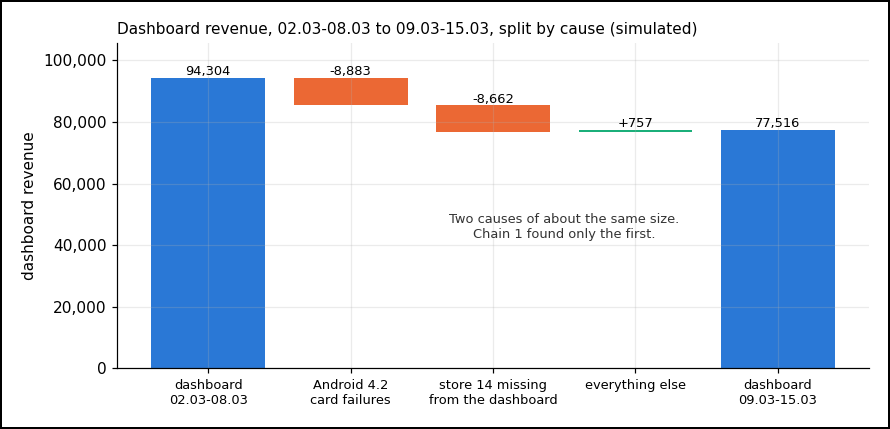

In [14]:
store_gap = missing["amount"].sum()
other = (r6 - r5) + android_est + store_gap
steps = [("dashboard\n02.03-08.03", r5, "total"), ("Android 4.2\ncard failures", -android_est, "step"),
         ("store 14 missing\nfrom the dashboard", -store_gap, "step"), ("everything else", other, "step"),
         ("dashboard\n09.03-15.03", r6, "total")]
print("What made up the 16,788 drop?")
print(f"  Android 4.2 card failures (estimate) = {-android_est:+,.0f}")
print(f"  store 14 missing from the dashboard = {-store_gap:+,.0f}")
print(f"  everything else (residual, not explained) = {other:+,.0f}")
print(f"      with the second Android estimate ({alt_est:,.0f}), everything else = {(r6 - r5) + alt_est + store_gap:+,.0f}")
print(f"  the two causes together = {android_est:,.0f} + {store_gap:,.0f} = {android_est + store_gap:,.0f}, which is {other:,.0f} more than the drop")
print(f"  total = {r6 - r5:+,.0f}")

fig, ax = plt.subplots(figsize=(8, 3.8))
level = 0
for i, (name, val, kind) in enumerate(steps):
    if kind == "total":
        ax.bar(i, val, color=BLUE); level = val
        ax.text(i, val + 900, f"{val:,.0f}", ha="center", fontsize=8.5)
    else:
        bottom = level + min(val, 0)
        ax.bar(i, abs(val), bottom=bottom, color=ORANGE if val < 0 else AQUA)
        ax.text(i, level + max(val, 0) + 900, f"{val:+,.0f}", ha="center", fontsize=8.5)
        level += val
ax.set_xticks(range(len(steps)), [s[0] for s in steps], fontsize=8.5)
ax.set_ylim(0, r5 * 1.12)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_ylabel("dashboard revenue")
ax.set_title("Dashboard revenue, 02.03-08.03 to 09.03-15.03, split by cause (simulated)", fontsize=10, loc="left")
ax.text(2.5, r5 * 0.45, "Two causes of about the same size.\nChain 1 found only the first.", ha="center", fontsize=8.5, color="#333333")
plt.tight_layout(); plt.show()

**Conclusion:** the drop has two causes of about the same size: Android version 4.2 rejecting two card types (about 8,883, an estimate) and store 14 missing from the dashboard (8,662). Chain 1 found the first and would have been reported as "the root cause". Chain 2 found the second, which is not even a real loss: the store's customers kept buying; the dashboard just stopped counting them.

**The truth, as planted in the simulation:** exactly these two causes, from 09.03 (version 4.2) and 11.03 (the store move).

**The lesson:** each "why" can have more than one true answer. Here the clue was at chain 1's Why 2, where the platforms that the Android cause could not explain also fell. A chain that keeps only the biggest answer will find only the biggest cause.

## Exercise — The next why

Chain 2 stopped at *"the store list is out of date, and orders from unlisted stores are dropped without a warning."* A teammate writes the next why as:

> *Why 5: why was the list out of date? Because the person who moved the store forgot to update it.*

What is wrong with this answer, and what is a better Why 5? Use the data on how many orders the dashboard dropped each week.

In [15]:
done_w = done.assign(week=done["date"].dt.to_period("W-SUN").dt.start_time)
dropped = done_w[~done_w["store_id"].isin(stores["store_id"])].groupby("week").size()
weeks = sorted(done_w["week"].unique())
print("Orders the dashboard dropped (store not on its list), by week:")
for w in weeks:
    print(f"  week of {pd.Timestamp(w):%d.%m} = {dropped.get(w, 0)}")

Orders the dashboard dropped (store not on its list), by week:
  week of 02.02 = 0
  week of 09.02 = 0
  week of 16.02 = 0
  week of 23.02 = 0
  week of 02.03 = 0
  week of 09.03 = 134


**Answer:** "someone forgot" stops at human error. It is probably true, and it changes nothing: people will forget again. The useful question is why forgetting could cost 8,662 of dashboard revenue without anyone noticing.

The data shows the dashboard dropped 0 orders a week for five weeks, then 134 in one week. **A better Why 5 (Hypothesis, to confirm with the dashboard's owner):** *the dashboard drops orders from unlisted stores without counting them, and nothing alerts on it.* That is a cause you can fix: add a check that alerts whenever the dashboard drops any order, or count unlisted stores as "unknown store" instead of dropping them.

## Key takeaways

- **The 5 Whys asks "why?" until the answer is something you can fix,** and every answer must be checked with data. Here chain 1 went: fewer orders → fewer Android orders → failing payments → version 4.2 → two card types rejected.
- **One chain finds one cause.** Chain 1 explained about 8,883 of the 16,788 drop (53%). A second chain found another 8,662: a store missing from the dashboard.
- **Watch for answers the chain leaves behind.** At chain 1's Why 2, web (−13%) and iOS (−11%) fell too, which an Android cause could not explain; with store 14 counted, they barely move.
- **Check the measurement first.** The dashboard and the order system agreed to the unit the week before, and differed by 8,662 this week.
- **Stop at what the data can check.** "Why does version 4.2 reject Mastercard and American Express?" has no data here, so it is a Hypothesis, not a step.
- **Do not stop at "human error".** "Someone forgot" is true but useless; "the dashboard drops orders silently" can be fixed.